In [1]:
import torch
import torch.nn as nn

In [2]:
torch.manual_seed(42)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = torch.Generator().manual_seed(42)

def generate_rings(n):
    points = []
    labels = []

    for label, radius in enumerate([1.0, 2.5, 4.0]):
        theta = torch.rand(n, generator=rng) * 2 * torch.pi
        r = radius + torch.randn(n, generator=rng) * 0.65

        x = r * torch.cos(theta)
        y = r * torch.sin(theta)

        ring = torch.stack((x, y), dim=1)

        points.append(ring)
        labels.extend([label] * n)

    X = torch.cat(points, dim=0)
    y = torch.tensor(labels, dtype=torch.long)

    indices = torch.randperm(len(X), generator=rng)

    return X[indices], y[indices]



X, y = generate_rings(1000)


In [ ]:
# ARCHITECTURE, 12 HIDDEN LAYERS
model = nn.Sequential(
    nn.Linear(2,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,16),
    nn.ReLU(),
    nn.Linear(16,3)
)

In [5]:
# RESIDUAL NETWORK
def forward(x):
    a = model[0](x)
    input_layer = model[1](a)
    a = model[2](input_layer)
    a = model[3](a)
    a = model[4](a)
    a = a + input_layer
    a = model[5](a)

    s1 = a
    a = model[6](a)
    a = model[7](a)
    a = model[8](a)
    a = a + s1
    a = model[9](a)

    s2 = a
    a = model[10](a)
    a = model[11](a)
    a = model[12](a)
    a = a + s2
    a = model[13](a)

    s3 = a
    a = model[14](a)
    a = model[15](a)
    a = model[16](a)
    a = a + s3
    a = model[17](a)

    s4 = a 
    a = model[18](a)
    a = model[19](a)
    a = model[20](a)
    a = a + s4
    a = model[21](a)

    a = model[22](a)
    a = model[23](a)
    a = model[24](a)

    return a

criterion = nn.CrossEntropyLoss()
output = forward(X)
loss = criterion(output,y)
print(loss.item())

1.1505911350250244


In [6]:
optimiser = torch.optim.SGD(model.parameters(),lr = 0.01)
for epoch in range(3000):
    output = forward(X)
    loss = criterion(output,y)

    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

    if epoch%10 == 0:
        print(f'EPOCH: {epoch}, LOSS: {loss}')
    

EPOCH: 0, LOSS: 1.1505911350250244
EPOCH: 10, LOSS: 1.110044002532959
EPOCH: 20, LOSS: 1.0873478651046753
EPOCH: 30, LOSS: 1.0733003616333008
EPOCH: 40, LOSS: 1.0629042387008667
EPOCH: 50, LOSS: 1.0543785095214844
EPOCH: 60, LOSS: 1.0468456745147705
EPOCH: 70, LOSS: 1.0396935939788818
EPOCH: 80, LOSS: 1.032670259475708
EPOCH: 90, LOSS: 1.0258071422576904
EPOCH: 100, LOSS: 1.0189332962036133
EPOCH: 110, LOSS: 1.0119142532348633
EPOCH: 120, LOSS: 1.0046898126602173
EPOCH: 130, LOSS: 0.9972097277641296
EPOCH: 140, LOSS: 0.9894331693649292
EPOCH: 150, LOSS: 0.9813256859779358
EPOCH: 160, LOSS: 0.9728529453277588
EPOCH: 170, LOSS: 0.9639716148376465
EPOCH: 180, LOSS: 0.9546446204185486
EPOCH: 190, LOSS: 0.9449059367179871
EPOCH: 200, LOSS: 0.9347298741340637
EPOCH: 210, LOSS: 0.9240425825119019
EPOCH: 220, LOSS: 0.9127771854400635
EPOCH: 230, LOSS: 0.9009160399436951
EPOCH: 240, LOSS: 0.8885359764099121
EPOCH: 250, LOSS: 0.8756757974624634
EPOCH: 260, LOSS: 0.862395167350769
EPOCH: 270, LOS

In [7]:
model.eval()
with torch.no_grad():
    output = forward(X)
    b = torch.argmax(output,dim = 1)
    c = (b == y)
    accuracy = c.float().mean()*100
print(f'TRAINING ACCURACY: {accuracy} %')

TRAINING ACCURACY: 84.03333282470703 %


In [8]:
X_test, y_test = generate_rings(300)

print("Training:", X.shape, y.shape)
print("Testing:", X_test.shape, y_test.shape)

model.eval()
with torch.no_grad():
    output = forward(X_test)
    prediction = torch.argmax(output,dim = 1)
    b = (prediction == y_test)
    accuracy = b.float().mean() * 100

print(f"TESTING ACCURACY: {accuracy} %")

Training: torch.Size([3000, 2]) torch.Size([3000])
Testing: torch.Size([900, 2]) torch.Size([900])
TESTING ACCURACY: 84.77777862548828 %


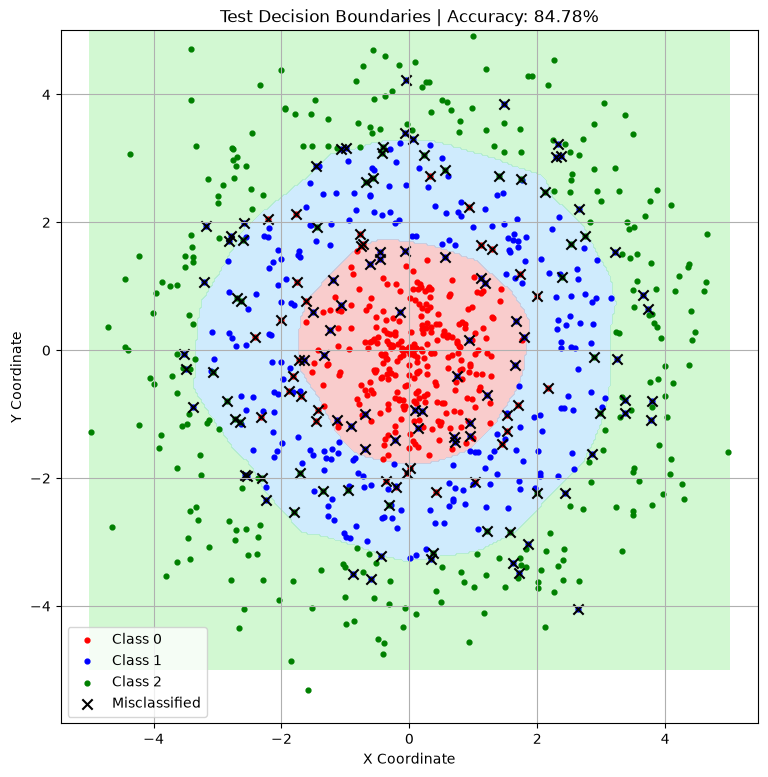

Test Accuracy: 84.78%
Misclassified Points: 137/900


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


x_values = np.linspace(-5, 5, 300)
y_values = np.linspace(-5, 5, 300)

xx, yy = np.meshgrid(x_values, y_values)

grid_points = np.column_stack((xx.ravel(), yy.ravel()))
grid_tensor = torch.tensor(grid_points, dtype=torch.float32)


model.eval()

with torch.no_grad():
    grid_predictions = torch.argmax(forward(grid_tensor), dim=1)
    test_predictions = torch.argmax(forward(X_test), dim=1)


pred = grid_predictions.reshape(xx.shape).numpy()


incorrect = (test_predictions != y_test)


accuracy = (test_predictions == y_test).float().mean() * 100


plt.figure(figsize=(9, 9))

plt.contourf(
    xx, yy, pred,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=['lightcoral', 'lightskyblue', 'lightgreen'],
    alpha=0.4
)

colors = ['red', 'blue', 'green']

for i in range(3):
    plt.scatter(
        X_test[y_test == i, 0],
        X_test[y_test == i, 1],
        color=colors[i],
        s=12,
        label=f'Class {i}'
    )


plt.scatter(
    X_test[incorrect, 0],
    X_test[incorrect, 1],
    marker='x',
    color='black',
    s=55,
    linewidths=1.5,
    label='Misclassified'
)

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title(f"Test Decision Boundaries | Accuracy: {accuracy.item():.2f}%")

plt.axis('equal')
plt.legend()
plt.grid(True)
plt.show()

print(f"Test Accuracy: {accuracy.item():.2f}%")
print(f"Misclassified Points: {incorrect.sum().item()}/900")